# 从零开始实现一个线性回归

In [51]:
%matplotlib inline
import random
import torch
from d2l import torch as d2l

## 生成数据集
手动构造一个1000 个样本的数据集,$\mathbf{X}$ 包含从标准正态中采样的两个特征，也就是横坐标中间密集，两边稀疏。

通过使用下面这个线性模型，其中 $\mathbf{w} = [2, -3.4]^\top$、$b = 4.2$
和噪声项$\epsilon$生成数据集及其标签：
$$\mathbf{y}= \mathbf{X} \mathbf{w} + b + \mathbf\epsilon.$$

$\epsilon$可以视为模型预测和标签时的潜在观测误差。
在这里我们认为标准假设成立，即$\epsilon$服从均值为0的正态分布。
为了简化问题，我们将标准差设为0.01，方差也就是0.0001。

In [52]:
def synthetic_data(w, b, num_examples):  #@save
    """生成y=Xw+b+噪声"""
    X = torch.normal(0, 1, (num_examples, len(w)))
    y = torch.matmul(X, w) + b
    y += torch.normal(0, 0.01, y.shape)
    return X, y.reshape((-1, 1))    #-1表示自动推断行数，1表示列数，
                                    #reshape 后从一维向量变为二维列向量


In [53]:
true_w = torch.tensor([2, -3.4])
true_b = 4.2
#X，y
features, labels = synthetic_data(true_w, true_b, 1000)

In [54]:
#X0,y0
print('features:', features[0],'\nlabel:', labels[0])

features: tensor([-0.8305, -0.3007]) 
label: tensor([3.5485])


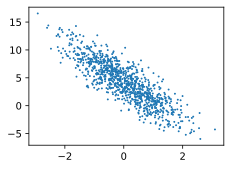

In [55]:
d2l.set_figsize()
d2l.plt.scatter(features[:, (1)].detach().numpy(), labels.detach().numpy(), 1);

## 读取数据集
训练模型时要对数据集进行遍历，每次抽取一小批量样本，并使用它们来更新我们的模型。
该函数能打乱数据集中的样本并以小批量方式获取数据。

函数最后返回用 yield，一个一个生成 batch，节省内存。如果用 return，你必须一次性把所有 batch 都生成出来存到一个列表里返回，1000 个样本就要占额外内存。

In [56]:
#生成大小为batch_size的小批量
def data_iter(batch_size, features, labels):
    num_examples = len(features)
    indices = list(range(num_examples)) #list(range(1000))=[0, 1, 2, 3, ..., 999]
    # 这些样本是随机读取的，没有特定的顺序
    random.shuffle(indices)
    for i in range(0, num_examples, batch_size):
        batch_indices = torch.tensor(
            indices[i: min(i + batch_size, num_examples)])
        yield features[batch_indices], labels[batch_indices]
        

In [57]:
batch_size = 10

for X, y in data_iter(batch_size, features, labels):
    print(X, '\n', y)
    break

tensor([[-2.0707,  0.7297],
        [-0.3082,  0.2011],
        [-1.1696,  1.0673],
        [-1.3189, -2.0733],
        [ 0.2667,  0.5506],
        [-0.3564,  0.0396],
        [-0.3817, -0.7534],
        [ 0.6092,  1.9633],
        [ 0.2747, -2.2827],
        [-0.9678, -0.0570]]) 
 tensor([[-2.4311],
        [ 2.8995],
        [-1.7727],
        [ 8.6108],
        [ 2.8553],
        [ 3.3734],
        [ 5.9981],
        [-1.2618],
        [12.5041],
        [ 2.4631]])


上面实现的执行效率很低。而且要求所有数据要加载到内存中，并执行大量的随机内存访问。

内置迭代器效率要高得多

## 初始化模型参数
在开始随机梯度下降优化模型参数之前，需要先初始化模型参数。下面先通过均值为 0，标准差为 0.01 的正态分布采样来初始化权重，并将偏置初始为 0.

In [58]:
w = torch.normal(0, 0.01, size=(2,1), requires_grad=True)
b = torch.zeros(1, requires_grad=True)

In [59]:
#定义模型
def linreg(X, w, b):  #@save
    """线性回归模型"""
    return torch.matmul(X, w) + b #matmul矩阵相乘

In [60]:
##定义损失函数
def squared_loss(y_hat, y):  #@save
    """均方损失"""
    return (y_hat - y.reshape(y_hat.shape)) ** 2 / 2

In [61]:
##定义优化算法
#params也就是[w, b]，lr 是 learning rate
def sgd(params, lr, batch_size):  #@save
    """小批量随机梯度下降"""
    with torch.no_grad():
        for param in params:
            param -= lr * param.grad / batch_size
            param.grad.zero_()

## 训练
在每次迭代中，我们读取一小批量训练样本。计算完损失后开始反向传播，存储每个参数的梯度。最后通过调用 优化算法`sgd`来更新模型参数。

概括一下，我们将执行以下循环：

* 初始化参数
* 重复以下训练，直到完成
    * 计算梯度$\mathbf{g} \leftarrow \partial_{(\mathbf{w},b)} \frac{1}{|\mathcal{B}|} \sum_{i \in \mathcal{B}} l(\mathbf{x}^{(i)}, y^{(i)}, \mathbf{w}, b)$
    * 更新参数$(\mathbf{w}, b) \leftarrow (\mathbf{w}, b) - \eta \mathbf{g}$



In [62]:
lr = 0.03
num_epochs = 3  #前两个都是超参数
net = linreg    #模型
loss = squared_loss #损失函数

In [63]:
for epoch in range(num_epochs):
    for X, y in data_iter(batch_size, features, labels):
        l = loss(net(X, w, b), y)  # X和y的小批量损失
        # 因为l形状是(batch_size,1)，而不是一个标量。l中的所有元素被加到一起，
        # 并以此计算关于[w,b]的梯度
        l.sum().backward()
        sgd([w, b], lr, batch_size)  # 使用参数的梯度更新参数
    with torch.no_grad():
        train_l = loss(net(features, w, b), labels)
        print(f'epoch {epoch + 1}, loss {float(train_l.mean()):f}')

epoch 1, loss 0.045895
epoch 2, loss 0.000200
epoch 3, loss 0.000053


In [64]:
#由于知道真实的参数是什么，可以得到真正的误差如下
print(f'w的估计误差: {true_w - w.reshape(true_w.shape)}')
print(f'b的估计误差: {true_b - b}')

w的估计误差: tensor([-0.0002, -0.0001], grad_fn=<SubBackward0>)
b的估计误差: tensor([0.0009], grad_fn=<RsubBackward1>)
